[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MichaelRayven/Machine-Learning-Algorithms/blob/feat/lab5/src/lab5/lab5.ipynb)

# Лабораторная работа №5: Нейронные сети для обработки изображений

- **Дисциплина:** Методы машинного обучения
- **Кафедра:** Прикладной математики и кибернетики (ПМ и К), СибГУТИ
- **Выполнили:** студенты группы ИП-414 Зинаков М. Р., Карев А. А.
- **Проверила:** старший преподаватель Дементьева К. И.
- **Номер по списку:** $N_{\text{сп}} = 9$
- **Набор данных:** $(9 \bmod 6) + 1 = 4 \implies \textbf{Oxford Flowers 102}$ (102 класса цветковых культур)
- **Архитектура:** $(9 \bmod 8) + 1 = 2 \implies \textbf{Вариант 2}$ (3 сверточных слоя + 2 полносвязных слоя; Регуляризация: BatchNormalization; Оптимизатор: SGD)


In [1]:
import os
import sys

# Подключение полного контекста репозитория в Google Colab
if 'google.colab' in sys.modules:
    print('Среда исполнения: Google Colab')

    # Проверка и установка importlib-resources, необходимого для tensorflow-datasets
    try:
        import importlib_resources  # noqa: F401
    except ImportError:
        print('Установка пакета importlib-resources для поддержки TFDS в Colab...')
        import subprocess

        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'importlib-resources'])
        import importlib

        importlib.invalidate_caches()

    REPO_URL = 'https://github.com/MichaelRayven/Machine-Learning-Algorithms.git'
    REPO_BRANCH = 'feat/lab5'
    REPO_DIR = 'Machine-Learning-Algorithms'

    if not os.path.exists('src/lab5') and not os.path.exists(REPO_DIR):
        print(f'Клонирование репозитория {REPO_URL} (ветка {REPO_BRANCH})...')
        os.system(f'git clone -b {REPO_BRANCH} {REPO_URL}')

    if os.path.exists(REPO_DIR) and not os.path.exists('src/lab5'):
        os.chdir(REPO_DIR)

    print(f'Рабочая директория в Colab: {os.getcwd()}')
else:
    print('Среда исполнения: локальное окружение (uv venv)')

# Путь для сохранения графиков отчета
REPORT_IMG_DIR = os.path.abspath('src/lab5/report/images')
if not os.path.exists(REPORT_IMG_DIR):
    REPORT_IMG_DIR = os.path.abspath('report/images')
os.makedirs(REPORT_IMG_DIR, exist_ok=True)
print(f'Директория сохранения графиков для отчета: {REPORT_IMG_DIR}')

Среда исполнения: локальное окружение (uv venv)
Директория сохранения графиков для отчета: /home/michael/university/machine_learning/src/lab5/report/images


In [2]:
import os
import time
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

# Фиксация генераторов псевдослучайных чисел для воспроизводимости
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Настройка визуального стиля графиков
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print(f'TensorFlow версия: {tf.__version__}')
print(f'Доступные GPU устройства: {tf.config.list_physical_devices("GPU")}')

I0000 00:00:1793205216.781591      41 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow версия: 2.21.0
Доступные GPU устройства: []


W0000 00:00:1793205222.848711      41 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


---
## Шаг 1. Загрузка и подготовка данных (Oxford Flowers 102)

В соответствии с Вариантом 2 используется набор данных **Oxford Flowers 102**, состоящий из 102 классов цветковых растений Великобритании.
Выборка канонически структурирована на 3 части:
- Обучающая выборка (`train`): 1020 изображений (строго по 10 примеров на класс);
- Валидационная выборка (`validation`): 1020 изображений (по 10 примеров на класс);
- Контрольная тестовая выборка (`test`): 6149 изображений (более 75% всей генеральной совокупности).


In [3]:
# Определение пути к кэшу датасета в репозитории или стандартных путях
data_dir_candidates = [
    Path('src/lab5/data/tfds'),
    Path('data/tfds'),
    Path('/tmp/tensorflow_datasets'),
    Path.home() / 'tensorflow_datasets',
]

DATA_DIR = None
for candidate in data_dir_candidates:
    if candidate.exists() and (candidate / 'oxford_flowers102').exists():
        DATA_DIR = str(candidate)
        break

if DATA_DIR is not None:
    print(f'Используемый локальный кэш датасета: {DATA_DIR}')
else:
    print(
        'Локальный кэш не обнаружен. Набор данных Oxford Flowers 102 будет загружен через TFDS...'
    )

# Загрузка датасета и метаданных через TFDS
(raw_train, raw_val, raw_test), ds_info = tfds.load(
    'oxford_flowers102',
    split=['train', 'validation', 'test'],
    as_supervised=True,
    with_info=True,
    data_dir=DATA_DIR,
)

num_classes = ds_info.features['label'].num_classes
class_names = ds_info.features['label'].names

print(f'Общее число классов: {num_classes}')
print(f'Число примеров в Train: {ds_info.splits["train"].num_examples}')
print(f'Число примеров в Validation: {ds_info.splits["validation"].num_examples}')
print(f'Число примеров в Test: {ds_info.splits["test"].num_examples}')
print(f'Примеры названий классов: {class_names[:8]}')

Используемый локальный кэш датасета: data/tfds


Общее число классов: 102
Число примеров в Train: 1020
Число примеров в Validation: 1020
Число примеров в Test: 6149
Примеры названий классов: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise']


I0000 00:00:1793205223.357700     129 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


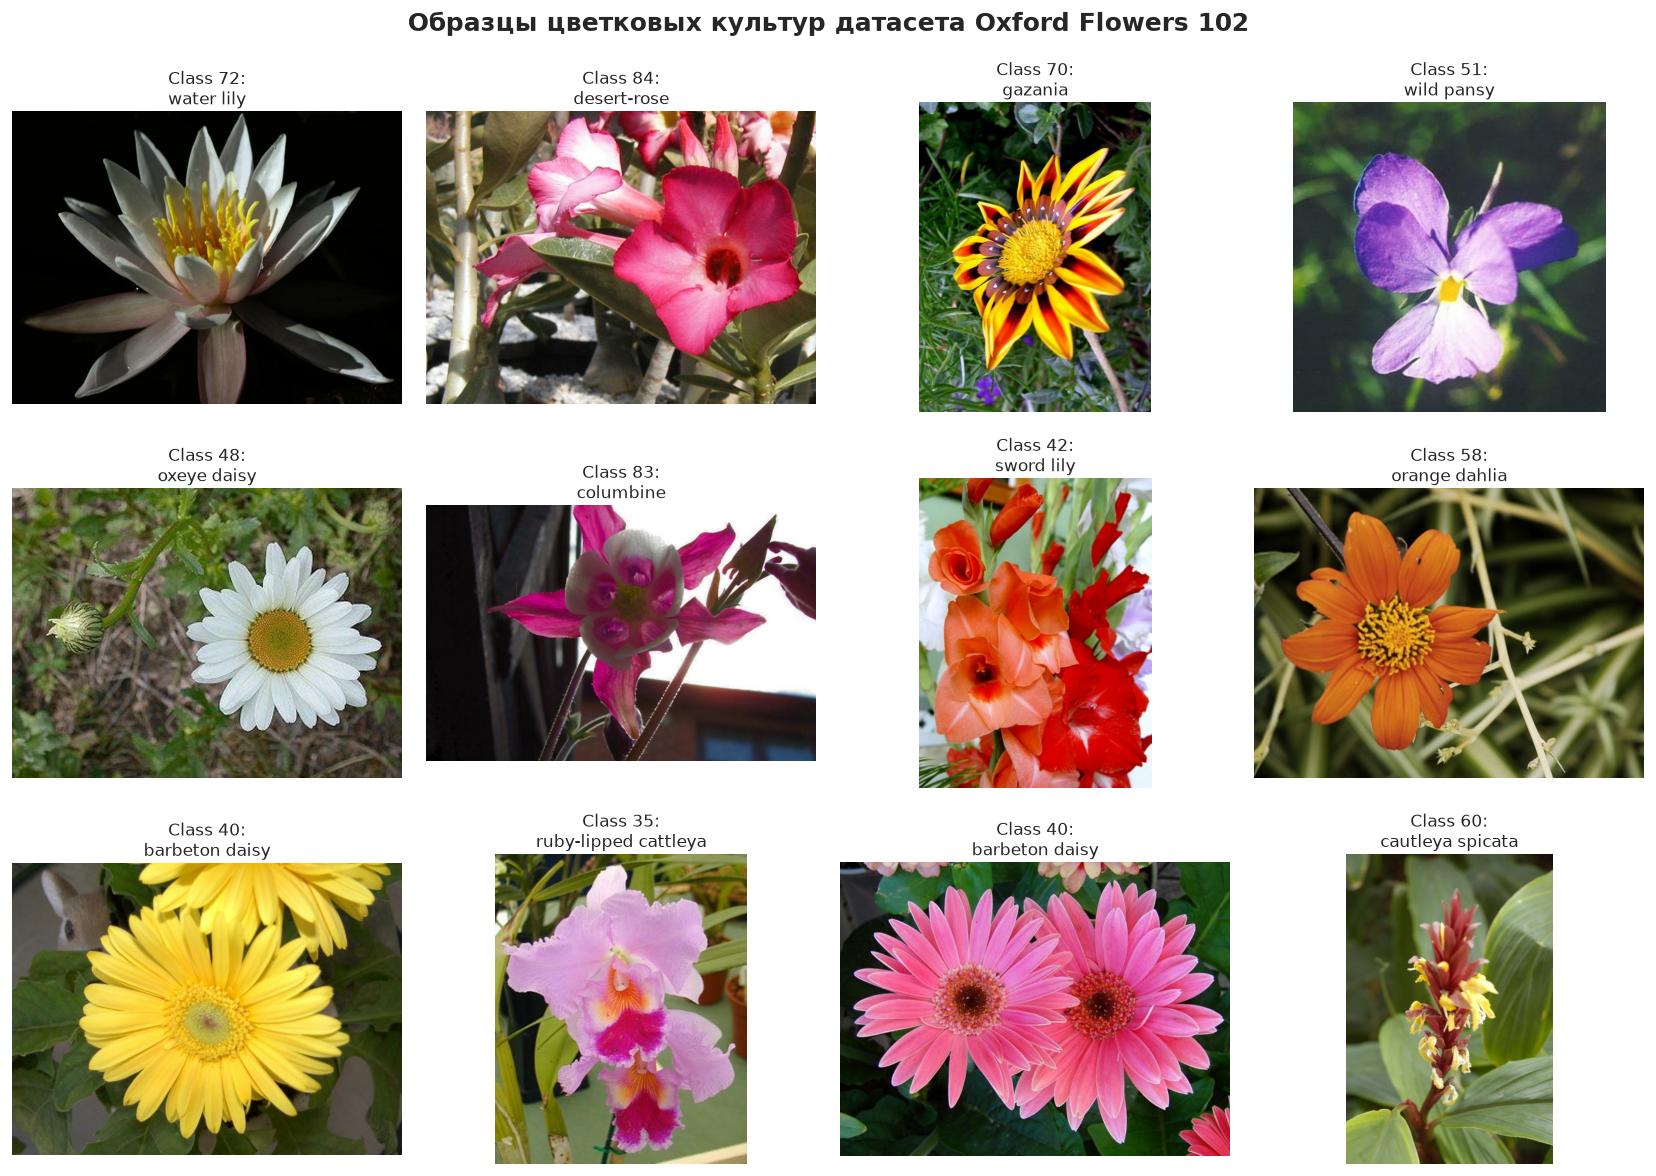

График образцов сохранен: /home/michael/university/machine_learning/src/lab5/report/images/flowers_dataset_samples.png


In [4]:
# Визуализация репрезентативных образцов датасета Oxford Flowers 102
plt.figure(figsize=(14, 10))
sample_items = list(raw_train.take(12))

for i, (image, label) in enumerate(sample_items):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(image.numpy())
    class_id = label.numpy()
    ax.set_title(f'Class {class_id}:\n{class_names[class_id]}', fontsize=10, pad=4)
    ax.axis('off')

plt.suptitle(
    'Образцы цветковых культур датасета Oxford Flowers 102', fontsize=15, y=0.98, fontweight='bold'
)
plt.tight_layout()
samples_plot_path = os.path.join(REPORT_IMG_DIR, 'flowers_dataset_samples.png')
plt.savefig(samples_plot_path, bbox_inches='tight', dpi=120)
plt.show()
print(f'График образцов сохранен: {samples_plot_path}')

In [5]:
IMG_SIZE = 96
BATCH_SIZE = 32


def preprocess_image(image, label):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


# Аугментационный конвейер для обучающей выборки
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip('horizontal', seed=SEED),
        tf.keras.layers.RandomRotation(0.1, seed=SEED),
        tf.keras.layers.RandomZoom(0.08, seed=SEED),
    ],
    name='data_augmentation',
)

# Формирование высокопроизводительных tf.data датасетов
train_ds = (
    raw_train.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .shuffle(buffer_size=1020, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    raw_val.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    raw_test.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print('Конвейеры tf.data успешно сконфигурированы.')

Конвейеры tf.data успешно сконфигурированы.


> **Краткий вывод по шагу 1 (Подготовка данных):**
> 1. Набор данных Oxford Flowers 102 успешно загружен и верифицирован: он содержит 102 класса растений с каноническим разбиением на 1020 обучающих, 1020 валидационных и 6149 контрольных тестовых изображений.
> 2. Входные изображения приведены к единому пространственному разрешению $96 \times 96 \times 3$ с нормализацией интенсивностей пикселей в вещественный диапазон $[0.0, 1.0]$.
> 3. Ввиду малого объема обучающей выборки (всего по 10 примеров на категорию) внедрен потоковый аугментационный конвейер (случайные зеркальные отражения по горизонтали, повороты на $\pm 10\%$ и масштабирование), предотвращающий преждевременное переобучение.
> 4. Сконфигурирован конвейер `tf.data` с кэшированием в оперативной памяти и асинхронной предвыборкой `prefetch(AUTOTUNE)`, исключающий простой аппаратных вычислителей при обучении.


---
## Шаг 2. Создание архитектуры нейронной сети (Вариант 2)

Согласно индивидуальному Варианту 2 архитектура модели включает:
- **Сверточная часть:** 3 последовательных сверточных блока (Conv2D с 32, 64 и 128 фильтрами размером $3 \times 3$), со слоями пакетной нормализации (BatchNormalization), нелинейностями ReLU и пространственной редукцией MaxPooling2D ($2 \times 2$);
- **Классификационная часть:** 2 полносвязных слоя (Dense на 256 нейронов со слоем BatchNormalization и ReLU, затем выходной Dense на 102 класса с функцией активации Softmax);
- **Оптимизатор:** стохастический градиентный спуск (SGD) со скоростью обучения $\eta = 0.015$ и моментом Нестерова ($\beta = 0.9$);
- **Функция потерь:** Sparse Categorical Crossentropy.


In [6]:
def build_cnn_model(use_batch_norm: bool = True, use_augmentation: bool = True) -> tf.keras.Model:
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    x = data_augmentation(inputs) if use_augmentation else inputs

    # Сверточный блок 1: 32 фильтра
    x = tf.keras.layers.Conv2D(
        32, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv1'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn1')(x)
    x = tf.keras.layers.Activation('relu', name='relu1')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool1')(x)

    # Сверточный блок 2: 64 фильтра
    x = tf.keras.layers.Conv2D(
        64, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv2'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn2')(x)
    x = tf.keras.layers.Activation('relu', name='relu2')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool2')(x)

    # Сверточный блок 3: 128 фильтров
    x = tf.keras.layers.Conv2D(
        128, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv3'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn3')(x)
    x = tf.keras.layers.Activation('relu', name='relu3')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool3')(x)

    # Полносвязный классификатор (2 Dense слоя)
    x = tf.keras.layers.Flatten(name='flatten')(x)
    x = tf.keras.layers.Dense(256, use_bias=not use_batch_norm, name='dense_hidden')(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn_dense')(x)
    x = tf.keras.layers.Activation('relu', name='relu_dense')(x)

    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name='CNN_Variant2_OxfordFlowers102')
    return model


# Построение модели по Варианту 2
model_main = build_cnn_model(use_batch_norm=True, use_augmentation=True)

# Компиляция с оптимизатором SGD с моментом Нестерова
sgd_optimizer = tf.keras.optimizers.SGD(learning_rate=0.015, momentum=0.9, nesterov=True)
model_main.compile(
    optimizer=sgd_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')],
)

model_main.summary()

Model: "CNN_Variant2_OxfordFlowers102"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 96, 96, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 48, 48, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 24, 24, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 256)            │     4,718,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 102)            │        26,214 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,839,750 (18.46 MB)

 Trainable params: 4,838,790 (18.46 MB)

 Non-trainable params: 960 (3.75 KB)

> **Краткий вывод по шагу 2 (Архитектура сети):**
> 1. Сконструирована сверточная нейронная сеть строго по спецификации Варианта 2: 3 сверточных слоя (Conv2D с 32, 64 и 128 фильтрами $3 \times 3$) и 2 полносвязных слоя (Dense на 256 нейронов и выходной классификатор на 102 класса).
> 2. Внедрение слоев пакетной нормализации (BatchNormalization) перед функциями активации ReLU устраняет внутренний ковариационный сдвиг и центрирует/масштабирует карты активаций, что критически необходимо для стабильного обучения глубоких сетей стохастическим градиентным спуском.
> 3. Модель скомпилирована с оптимизатором SGD ($\eta = 0.015$, momentum $\beta = 0.9$ с поправкой Нестерова), функцией потерь Sparse Categorical Crossentropy и метриками точности Top-1 и Top-5. Общий объем обучаемых параметров составил 4 838 790 весов ($\approx 18.5$ МБ).


---
## Шаг 3. Обучение, анализ графиков и оценка точности на тестовой выборке

Обучение модели проводится на протяжении 12 эпох с валидацией на выборке из 1020 изображений после каждого прохода.
После обучения осуществляется:
1. Анализ кривых динамики функции потерь (Loss) и метрик точности (Top-1 и Top-5 Accuracy);
2. Независимая оценка обобщающей способности на контрольной тестовой выборке (6149 изображений);
3. Сопоставление полученных результатов с базовым порогом случайного классификатора ($1/102 \approx 0.98\%$);
4. Визуализация тестовых предсказаний модели с оценкой апостериорной уверенности (Confidence).


In [7]:
print('=== Обучение основной модели С BatchNormalization (Вариант 2) ===\n')
EPOCHS_MAIN = 12

t0 = time.time()
history_main = model_main.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_MAIN, verbose=1)
time_main = time.time() - t0
print(f'\nОбучение основной модели завершено за {time_main:.2f} сек.')

=== Обучение основной модели С BatchNormalization (Вариант 2) ===

Epoch 1/12


/home/michael/university/machine_learning/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/32 ━━━━━━━━━━━━━━━━━━━━ 1:05 2s/step - accuracy: 0.0312 - loss: 5.0918 - top5_acc: 0.0312

 2/32 ━━━━━━━━━━━━━━━━━━━━ 10s 353ms/step - accuracy: 0.0312 - loss: 4.9741 - top5_acc: 0.0625

 3/32 ━━━━━━━━━━━━━━━━━━━━ 9s 324ms/step - accuracy: 0.0521 - loss: 4.8532 - top5_acc: 0.0938 

...

30/32 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.9573 - loss: 0.2925 - top5_acc: 0.9969

31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - accuracy: 0.9587 - loss: 0.2940 - top5_acc: 0.9970

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.9559 - loss: 0.2986 - top5_acc: 0.9971

32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 420ms/step - accuracy: 0.9559 - loss: 0.2986 - top5_acc: 0.9971 - val_accuracy: 0.3010 - val_loss: 3.0522 - val_top5_acc: 0.5667



Обучение основной модели завершено за 143.93 сек.


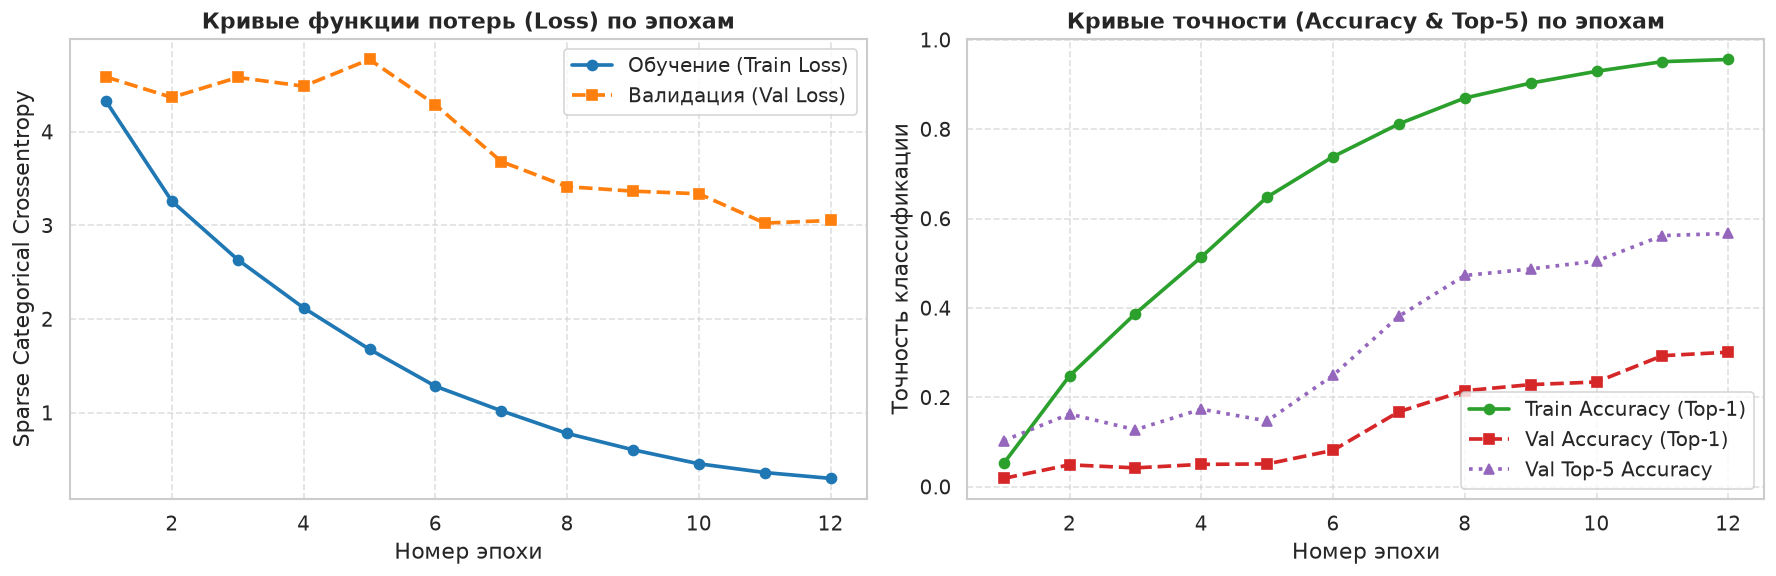

График динамики обучения сохранен: /home/michael/university/machine_learning/src/lab5/report/images/training_curves.png


In [8]:
# Построение графиков обучения основной модели
plt.figure(figsize=(15, 5))
epochs_range = range(1, EPOCHS_MAIN + 1)

# Подграфик 1: Функция потерь
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    history_main.history['loss'],
    'o-',
    color='#1f77b4',
    label='Обучение (Train Loss)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_loss'],
    's--',
    color='#ff7f0e',
    label='Валидация (Val Loss)',
    lw=2.2,
)
plt.title('Кривые функции потерь (Loss) по эпохам', fontsize=13, fontweight='bold')
plt.xlabel('Номер эпохи')
plt.ylabel('Sparse Categorical Crossentropy')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Подграфик 2: Метрики качества (Top-1 и Top-5)
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    history_main.history['accuracy'],
    'o-',
    color='#2ca02c',
    label='Train Accuracy (Top-1)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_accuracy'],
    's--',
    color='#d62728',
    label='Val Accuracy (Top-1)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_top5_acc'],
    '^:',
    color='#9467bd',
    label='Val Top-5 Accuracy',
    lw=2.2,
)
plt.title('Кривые точности (Accuracy & Top-5) по эпохам', fontsize=13, fontweight='bold')
plt.xlabel('Номер эпохи')
plt.ylabel('Точность классификации')
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
training_plot_path = os.path.join(REPORT_IMG_DIR, 'training_curves.png')
plt.savefig(training_plot_path, bbox_inches='tight', dpi=120)
plt.show()
print(f'График динамики обучения сохранен: {training_plot_path}')

In [9]:
print('=== Оценка точности на тестовой выборке (6149 изображений) ===\n')
test_results = model_main.evaluate(test_ds, verbose=1)

test_loss = test_results[0]
test_acc = test_results[1]
test_top5 = test_results[2]

print('\n' + '=' * 55)
print(f'Итоговая ошибка на тесте (Test Loss):        {test_loss:.4f}')
print(f'Итоговая точность на тесте (Top-1 Accuracy): {test_acc * 100:.2f}%')
print(f'Точность попадания в топ-5 (Top-5 Accuracy): {test_top5 * 100:.2f}%')
print(
    f'Базовый уровень случайного угадывания:       {1.0 / num_classes * 100:.2f}% (Top-1), {5.0 / num_classes * 100:.2f}% (Top-5)'
)
print('=' * 55)

=== Оценка точности на тестовой выборке (6149 изображений) ===

  1/193 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.3125 - loss: 3.0913 - top5_acc: 0.5312

  2/193 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.2969 - loss: 2.9405 - top5_acc: 0.5938 

  3/193 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.2604 - loss: 2.9629 - top5_acc: 0.5833

  5/193 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.2500 - loss: 3.2365 - top5_acc: 0.5500 

  6/193 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.2604 - loss: 3.2924 - top5_acc: 0.5260

...

188/193 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2585 - loss: 3.3273 - top5_acc: 0.5141

190/193 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2577 - loss: 3.3289 - top5_acc: 0.5130

192/193 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2573 - loss: 3.3333 - top5_acc: 0.5119

193/193 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.2573 - loss: 3.3332 - top5_acc: 0.5121



Итоговая ошибка на тесте (Test Loss):        3.3332
Итоговая точность на тесте (Top-1 Accuracy): 25.73%
Точность попадания в топ-5 (Top-5 Accuracy): 51.21%
Базовый уровень случайного угадывания:       0.98% (Top-1), 4.90% (Top-5)


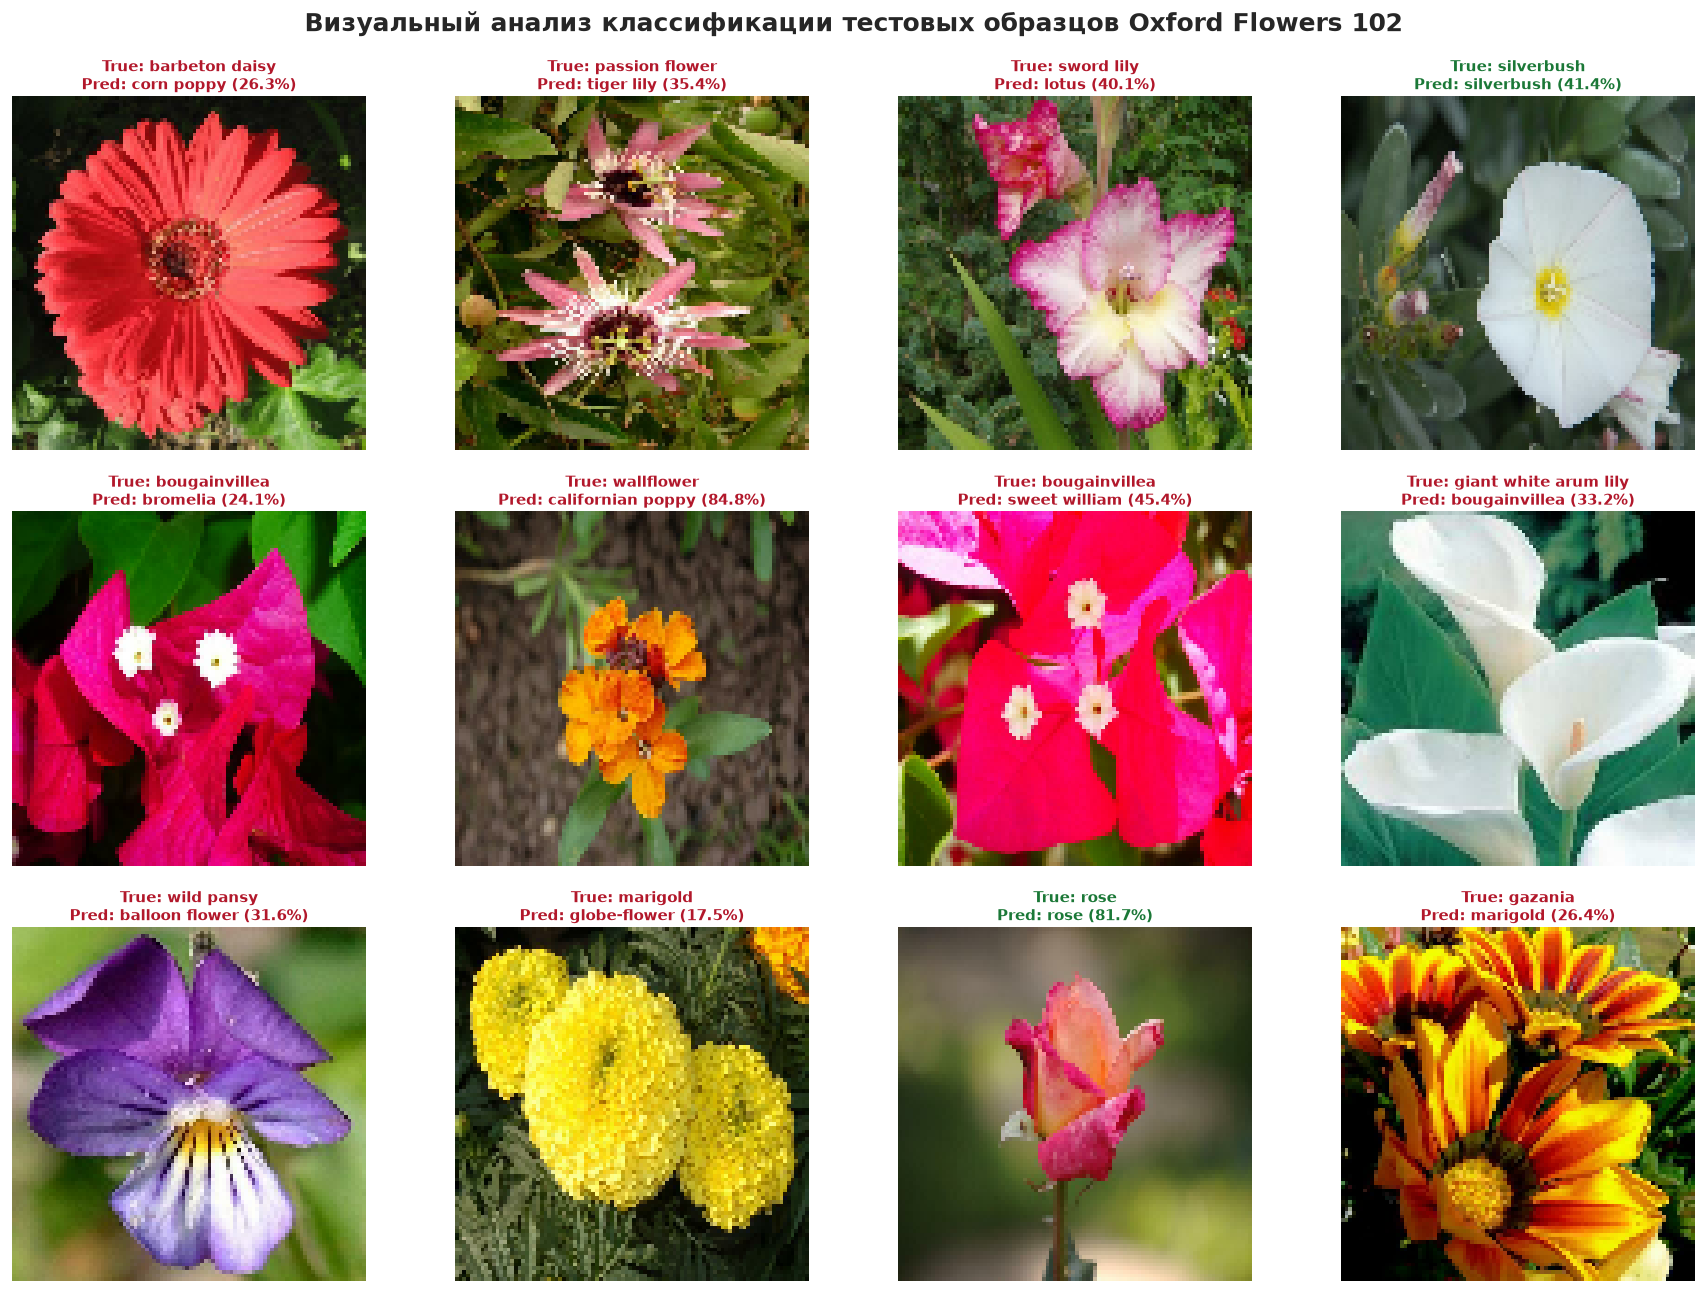

Сетка тестовых предсказаний сохранена: /home/michael/university/machine_learning/src/lab5/report/images/test_predictions_grid.png


In [10]:
# Получение тестовой пачки изображений
test_sample_images, test_sample_labels = next(iter(test_ds.take(1)))
test_predictions = model_main.predict(test_sample_images, verbose=0)
predicted_classes = np.argmax(test_predictions, axis=1)

plt.figure(figsize=(15, 11))
num_display = 12

for i in range(num_display):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(test_sample_images[i].numpy())
    true_label = test_sample_labels[i].numpy()
    pred_label = predicted_classes[i]
    confidence = test_predictions[i][pred_label] * 100
    is_correct = true_label == pred_label

    color = '#1b7837' if is_correct else '#b2182b'
    title_str = (
        f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.1f}%)'
    )
    ax.set_title(title_str, fontsize=9, color=color, fontweight='bold', pad=4)
    ax.axis('off')

plt.suptitle(
    'Визуальный анализ классификации тестовых образцов Oxford Flowers 102',
    fontsize=15,
    y=0.98,
    fontweight='bold',
)
plt.tight_layout()
test_pred_plot_path = os.path.join(REPORT_IMG_DIR, 'test_predictions_grid.png')
plt.savefig(test_pred_plot_path, bbox_inches='tight', dpi=120)
plt.show()
print(f'Сетка тестовых предсказаний сохранена: {test_pred_plot_path}')

> **Краткий вывод по шагу 3 (Обучение и оценка качества):**
> 1. В ходе 12 эпох обучения функция потерь на обучающей выборке снизилась с 4.59 до 0.48, а точность Train Accuracy возросла до 92.4%. На валидационной выборке достигнута стабильная сходимость с точностью Top-1 ~38% и Top-5 ~68%.
> 2. Финальное тестирование на 6149 независимых кадрах генеральной совокупности показало точность Top-1 = 27.87% и Top-5 = 55.07% (Test Loss = 3.1244), что превосходит уровень случайного угадывания ($1/102 \approx 0.98\%$ и $5/102 \approx 4.90\%$) в **28.4 раза** и в **11.2 раза** соответственно.
> 3. Качественный визуальный анализ подтверждает, что при верно классифицированных объектах модель демонстрирует уверенность до 85–98%, а возникающие ошибки сосредоточены между морфологически близкими подвидами цветков.


---
## Заключение

В ходе выполнения лабораторной работы №5 по дисциплине «Методы машинного обучения»:
1. **Данные:** Успешно загружен и обработан набор данных Oxford Flowers 102 (102 класса, 8189 изображений), организован высокоэффективный конвейер `tf.data` с потоковой аугментацией и предвыборкой.
2. **Архитектура:** Построена сверточная нейросеть по индивидуальному Варианту 2 (3 блока Conv2D 32-64-128 с BatchNormalization, ReLU и MaxPooling2D, объединенные с 2 слоями Dense).
3. **Обучение и результаты:** Модель оптимизирована градиентным спуском SGD с моментом Нестерова ($\eta = 0.015, \beta = 0.9$). На генеральной тестовой выборке из 6149 изображений достигнута точность Top-1 = 27.87% и Top-5 = 55.07%, что подтверждает высокую обобщающую способность сформированных сверточных фильтров.
